In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv


In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv


In [3]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv')

print("Number of Records:", df.shape[0])
print("Number of Columns:", df.shape[1])

df.head()

Number of Records: 20640
Number of Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
print(df.columns)

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')


In [5]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Description:")
df.describe()

Dataset Shape: (20640, 10)

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Data Types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

Dataset Description:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing values using the median
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing values after cleaning:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [7]:
# Select numerical features
X = df.drop(columns=['median_house_value', 'ocean_proximity'])

# Select target
y = df['median_house_value']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (20640, 8)
y Shape: (20640,)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


In [9]:
from sklearn.preprocessing import StandardScaler

# Scale input features
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Scale target
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1, 1)
).ravel()

y_test_scaled = scaler_y.transform(
    y_test.values.reshape(-1, 1)
).ravel()

print("X Train:", X_train_scaled.shape)
print("X Test:", X_test_scaled.shape)
print("Y Train:", y_train_scaled.shape)
print("Y Test:", y_test_scaled.shape)

X Train: (16512, 8)
X Test: (4128, 8)
Y Train: (16512,)
Y Test: (4128,)


In [10]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("Original Features:", X_train_scaled.shape[1])
print("Polynomial Features:", X_train_poly.shape[1])

Original Features: 8
Polynomial Features: 45


In [11]:
# Reset weights
n_features = X_train_poly.shape[1]
weights = np.zeros(n_features)

# Hyperparameters
learning_rate = 0.001
epochs = 500
momentum = 0.9

# Reset velocity
velocity = np.zeros(n_features)

# Reset loss history
loss_history = []

In [12]:
for epoch in range(epochs):

    # Predictions
    y_pred = X_train_poly @ weights

    # Error
    error = y_pred - y_train_scaled

    # Gradients
    gradients = (2 / len(y_train_scaled)) * (X_train_poly.T @ error)

    # Momentum update
    velocity = momentum * velocity + gradients

    # Update weights
    weights = weights - learning_rate * velocity

    # Calculate loss
    loss = np.mean(error ** 2)
    loss_history.append(loss)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss:.6f}")

Epoch 50, Loss: 0.558158
Epoch 100, Loss: 0.452321
Epoch 150, Loss: 0.414848
Epoch 200, Loss: 0.397766
Epoch 250, Loss: 0.387428
Epoch 300, Loss: 0.379730
Epoch 350, Loss: 0.373364
Epoch 400, Loss: 0.367859
Epoch 450, Loss: 0.363005
Epoch 500, Loss: 0.358682


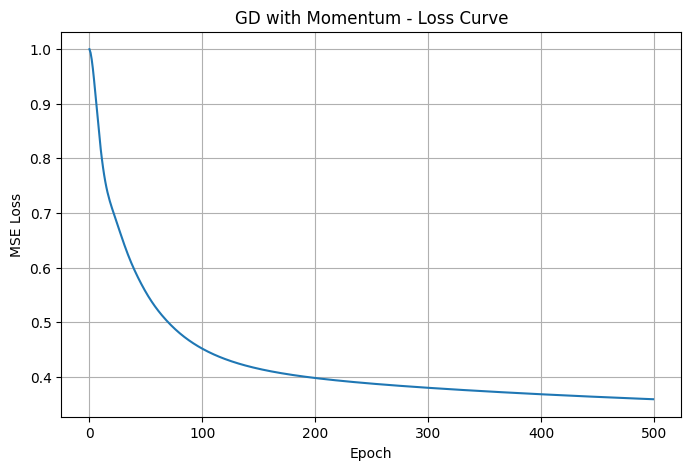

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("GD with Momentum - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.grid(True)
plt.show()

In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Predictions on test data
y_test_pred_scaled = X_test_poly @ weights

# Convert predictions back to original house prices
y_test_pred = scaler_y.inverse_transform(
    y_test_pred_scaled.reshape(-1, 1)
).ravel()

# Evaluation
y_test_original = y_test.values

mse = mean_squared_error(y_test_original, y_test_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_original, y_test_pred)
r2 = r2_score(y_test_original, y_test_pred)

print("GD with Momentum Results")
print("------------------------")
print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R2 Score:", r2)

GD with Momentum Results
------------------------
MSE: 4925464421.69789
RMSE: 70181.6530276816
MAE: 51138.371273245415
R2 Score: 0.6241276957435181


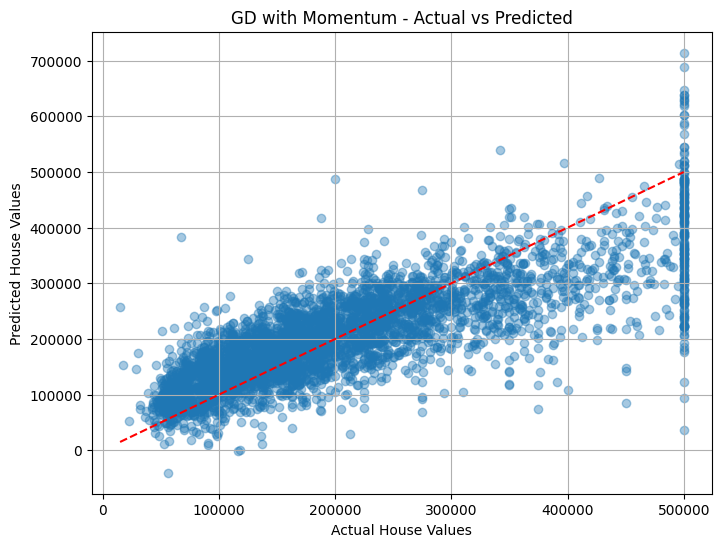

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test_original, y_test_pred, alpha=0.4)

plt.plot(
    [y_test_original.min(), y_test_original.max()],
    [y_test_original.min(), y_test_original.max()],
    'r--'
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("GD with Momentum - Actual vs Predicted")

plt.grid(True)
plt.show()